In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Data Cleaning

In [41]:
df = pd.read_excel("/content/Online Retail.xlsx")
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [42]:
df.info()
print(df.isna().sum())
print("Duplicates:",df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicates: 5268


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [43]:
#cancelled invoices start with C
cancelled = df[df["InvoiceNo"].astype(str).str.startswith("C")]
print("Cancelled rows:", len(cancelled))
print(cancelled[["InvoiceNo", "Quantity", "UnitPrice"]].head())

Cancelled rows: 9288
    InvoiceNo  Quantity  UnitPrice
141   C536379        -1      27.50
154   C536383        -1       4.65
235   C536391       -12       1.65
236   C536391       -24       0.29
237   C536391       -24       0.29


In [44]:
non_cancelled = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
print("Quantity <= 0:", (non_cancelled["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (non_cancelled["UnitPrice"] <= 0).sum())

Quantity <= 0: 1336
UnitPrice <= 0: 2517


In [45]:
df.nlargest(5, "UnitPrice")[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID"]]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
222681,C556445,M,Manual,-1,38970.00,15098.0
524602,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,NaN
43702,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,NaN
43703,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,NaN
15016,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN


In [46]:
df_clean = df.copy()

df_clean= df_clean.dropna(subset=["CustomerID"])
df_clean["CustomerID"]=df_clean["CustomerID"].astype(int)

df_clean= df_clean.drop_duplicates()

df_clean["InvoiceNo"]= df_clean["InvoiceNo"].astype(str)
df_clean= df_clean[~df_clean["InvoiceNo"].str.startswith("C")]

df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["UnitPrice"] > 0)]

df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print("Before:", df.shape, "| After:", df_clean.shape)
print("Remaining missing:\n", df_clean.isna().sum())

Before: (541909, 8) | After: (392692, 9)
Remaining missing:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64


In [47]:
non_product = df_clean[~df_clean["StockCode"].astype(str).str.match(r"^\d{5}")]
print(non_product.groupby(["StockCode", "Description"]).size().sort_values(ascending=False).head(15))

StockCode     Description               
POST          POSTAGE                       1099
M             Manual                         279
C2            CARRIAGE                       133
DOT           DOTCOM POSTAGE                  16
BANK CHARGES  Bank Charges                    12
PADS          PADS TO MATCH ALL CUSHIONS       3
dtype: int64


In [48]:
non_product_codes = ["POST", "M", "C2", "DOT", "BANK CHARGES"]
df_clean = df_clean[~df_clean["StockCode"].isin(non_product_codes)]

print("Final shape:", df_clean.shape)
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Date range:", df_clean["InvoiceDate"].min(), "->", df_clean["InvoiceDate"].max())

Final shape: (391153, 9)
Unique customers: 4334
Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


In [49]:
df_clean[["Quantity","UnitPrice","TotalPrice"]].describe()

,Quantity,UnitPrice,TotalPrice
count,391153.000000,391153.000000,391153.000000
mean,13.145207,2.874350,22.337110
std,180.807141,4.284729,310.931256
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,11.900000
75%,12.000000,3.750000,19.800000
max,80995.000000,649.500000,168469.600000


# EDA

In [50]:
country_stats = df_clean.groupby("Country").agg(
    Transactions=("InvoiceNo", "nunique"),
    Revenue=("TotalPrice", "sum"),
    Customers=("CustomerID", "nunique"),
).sort_values("Revenue", ascending=False)

print(country_stats.head(10))

                Transactions      Revenue  Customers
Country                                             
United Kingdom         16579  7242855.323       3916
Netherlands               93   283889.340          9
EIRE                     256   257013.120          3
Germany                  443   205381.150         94
France                   379   183801.940         87
Australia                 56   138103.810          9
Spain                     88    55706.560         30
Switzerland               47    52441.950         21
Japan                     19    37416.370          8
Belgium                   98    36927.340         25


/tmp/ipykernel_2173/2857200352.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = df_clean.set_index("InvoiceDate")["TotalPrice"].resample("M").sum()


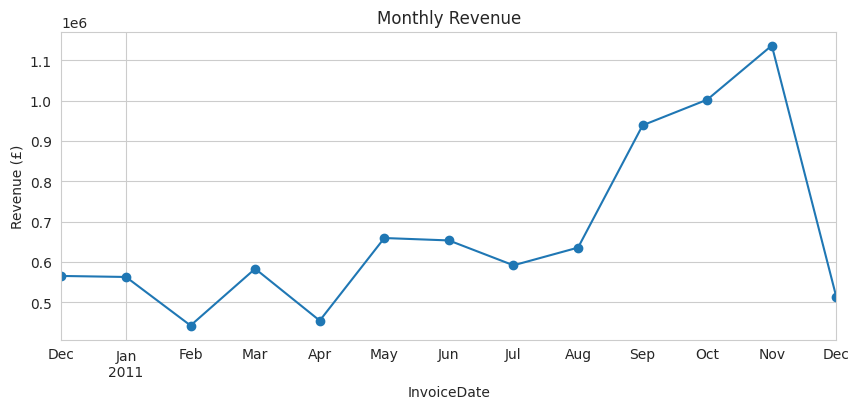

In [51]:
monthly = df_clean.set_index("InvoiceDate")["TotalPrice"].resample("M").sum()

plt.figure(figsize=(10, 4))
monthly.plot(marker="o", title="Monthly Revenue")
plt.ylabel("Revenue (£)")
plt.show()

In [52]:
df_clean.nlargest(5, "TotalPrice")[["InvoiceNo", "Description", "Quantity", "UnitPrice", "TotalPrice", "CustomerID"]]

,InvoiceNo,Description,Quantity,UnitPrice,TotalPrice,CustomerID
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346
222680,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098
348325,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749


In [53]:
ids = [16446, 12346, 15098]
check = df[
    df["CustomerID"].isin(ids)
    & df["InvoiceNo"].astype(str).str.startswith("C")
    & (df["Quantity"] <= -60)
]
check[["InvoiceNo", "Description", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID"]].sort_values("CustomerID")

,InvoiceNo,Description,Quantity,UnitPrice,InvoiceDate,CustomerID
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00,12346.0
222692,C556448,PICNIC BASKET WICKER SMALL,-60,4.95,2011-06-10 15:39:00,15098.0
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00,16446.0


In [54]:
# 1) الإلغاءات من الداتا الأصلية (بعد ما نشيل اللي من غير ID)
cancel = df[df["InvoiceNo"].astype(str).str.startswith("C")].dropna(subset=["CustomerID"])
cancel_keys = set(zip(cancel["CustomerID"].astype(int), cancel["StockCode"], -cancel["Quantity"]))

# 2) علّمي المشتريات اللي ليها إلغاء مقابل
mask = pd.Series(
    [(c, s, q) in cancel_keys
     for c, s, q in zip(df_clean["CustomerID"], df_clean["StockCode"], df_clean["Quantity"])],
    index=df_clean.index,
)
print("Purchases with a matching cancellation:", mask.sum())

# 3) شيليها
df_clean = df_clean[~mask]

# 4) حالة العميل 15098 يدويًا (إلغاؤها اتسجّل في صف Manual)
df_clean = df_clean[df_clean["InvoiceNo"] != "556444"]

print("New shape:", df_clean.shape)
df_clean.nlargest(5, "TotalPrice")[["InvoiceNo", "Description", "Quantity", "TotalPrice", "CustomerID"]]

Purchases with a matching cancellation: 5221
New shape: (385932, 9)


,InvoiceNo,Description,Quantity,TotalPrice,CustomerID
348325,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,7144.72,17450
421601,573003,RABBIT NIGHT LIGHT,2400,4992.00,14646
244419,558526,REGENCY TEAPOT ROSES,540,4401.00,17949
291249,562439,ASSORTED COLOUR BIRD ORNAMENT,2880,4176.00,12931
52134,540689,HEART OF WICKER LARGE,1284,4121.64,17450


In [55]:
print(df_clean["CustomerID"].nunique())
df_clean[["Quantity", "UnitPrice", "TotalPrice"]].describe()

4321


,Quantity,UnitPrice,TotalPrice
count,385932.000000,385932.000000,385932.000000
mean,12.598124,2.845433,21.245774
std,41.455636,3.968927,66.309506
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.850000,11.900000
75%,12.000000,3.750000,19.800000
max,4800.000000,649.500000,7144.720000


In [56]:
df_clean[df_clean["UnitPrice"] < 0.1][["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID"]].head(10)

,InvoiceNo,Description,Quantity,UnitPrice,CustomerID
14788,537618,PORCELAIN BUDAH INCENSE HOLDER,100,0.070,15061
91772,544152,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,2400,0.060,14609
112953,545905,BLUE STONES ON WIRE FOR CANDLE,24,0.080,15234
157195,550193,PADS TO MATCH ALL CUSHIONS,1,0.001,13952
170361,551291,PORCELAIN BUDAH INCENSE HOLDER,200,0.070,14298
170392,551291,SMALL FOLDING SCISSOR(POINTED EDGE),240,0.080,14298
170957,551351,PAPER POCKET TRAVELING FAN,240,0.070,14298
177435,552062,BLUE STONES ON WIRE FOR CANDLE,24,0.080,13117
195806,553747,BLUE STONES ON WIRE FOR CANDLE,24,0.080,13627
210605,555284,PAPER POCKET TRAVELING FAN,240,0.070,14298


In [57]:
country_stats = df_clean.groupby("Country").agg(
    Transactions=("InvoiceNo", "nunique"),
    Revenue=("TotalPrice", "sum"),
    Customers=("CustomerID", "nunique"),
).sort_values("Revenue", ascending=False)
print(country_stats.head(10))

                Transactions      Revenue  Customers
Country                                             
United Kingdom         16376  6743498.053       3906
Netherlands               92   282161.940          9
EIRE                     250   236941.810          3
Germany                  441   203089.880         94
France                   372   180845.390         87
Australia                 51   136919.900          9
Spain                     86    51929.220         29
Switzerland               44    51859.300         21
Japan                     19    37212.370          8
Belgium                   98    36813.690         25


/tmp/ipykernel_2173/2857200352.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = df_clean.set_index("InvoiceDate")["TotalPrice"].resample("M").sum()


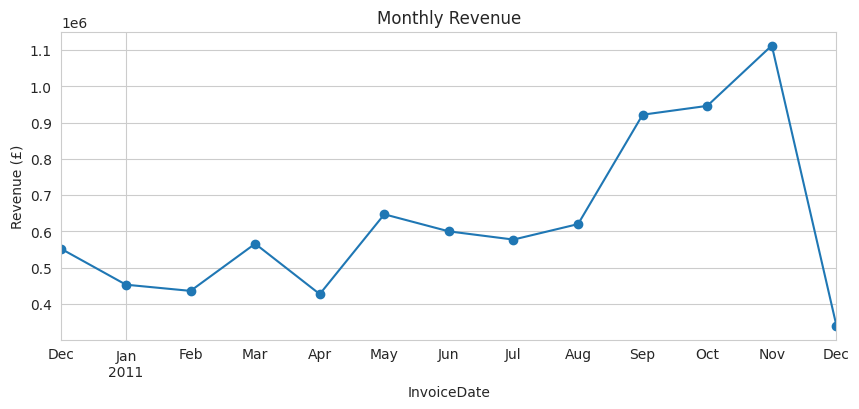

In [58]:
monthly = df_clean.set_index("InvoiceDate")["TotalPrice"].resample("M").sum()

plt.figure(figsize=(10, 4))
monthly.plot(marker="o", title="Monthly Revenue")
plt.ylabel("Revenue (£)")
plt.show()

In [59]:
df_clean = df_clean[df_clean["UnitPrice"] >= 0.01]

# Feature Engineering

In [60]:
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
)

print(rfm.shape)
rfm.head()

(4321, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12347,2,7,4310.00
12348,75,4,1437.24
12349,19,1,1457.55
12350,310,1,294.40
12352,36,5,1125.28


In [61]:
rfm.describe()

,Recency,Frequency,Monetary
count,4321.000000,4321.000000,4321.000000
mean,93.056006,4.203194,1897.575538
std,100.413809,7.510943,8190.549201
min,1.000000,1.000000,2.900000
25%,18.000000,1.000000,301.290000
50%,51.000000,2.000000,653.750000
75%,144.000000,5.000000,1608.100000
max,374.000000,202.000000,277460.420000


# Preprocessing

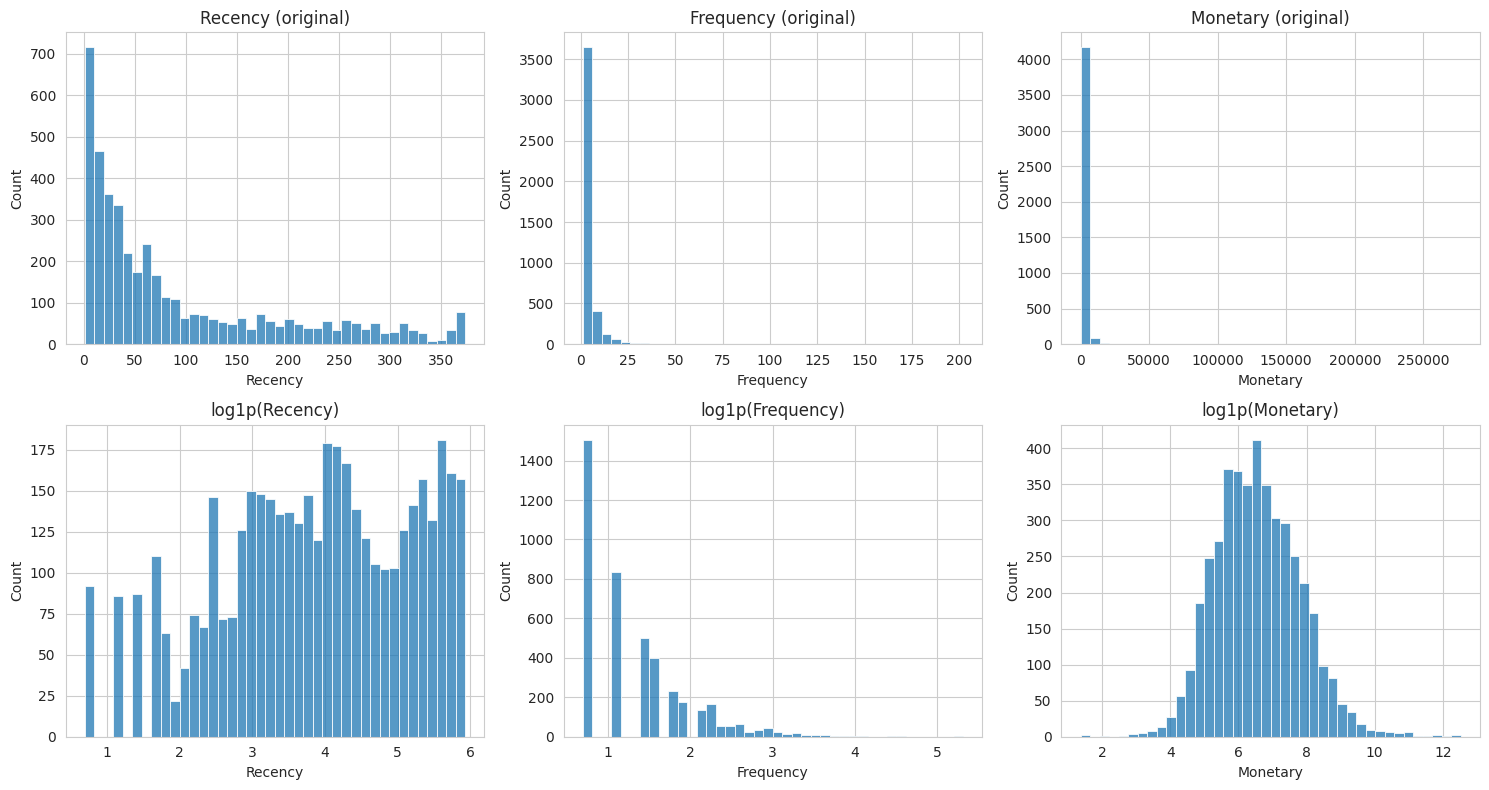

In [62]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax[0, i]).set_title(f"{col} (original)")
    sns.histplot(np.log1p(rfm[col]), bins=40, ax=ax[1, i]).set_title(f"log1p({col})")
plt.tight_layout()
plt.show()

In [63]:
print("Skewness before:\n", rfm[["Recency", "Frequency", "Monetary"]].skew().round(2))
print("\nSkewness after log:\n", np.log1p(rfm[["Recency", "Frequency", "Monetary"]]).skew().round(2))

Skewness before:
 Recency       1.24
Frequency    11.80
Monetary     21.98
dtype: float64

Skewness after log:
 Recency     -0.38
Frequency    1.22
Monetary     0.36
dtype: float64


Scaling

In [64]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [65]:
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)

print(pd.DataFrame(X, columns=rfm_log.columns).describe().round(2))

       Recency  Frequency  Monetary
count  4321.00    4321.00   4321.00
mean      0.00      -0.00      0.00
std       1.00       1.00      1.00
min      -2.34      -0.95     -4.17
25%      -0.66      -0.95     -0.68
50%       0.09      -0.35     -0.06
75%       0.85       0.67      0.66
max       1.56       5.86      4.80


# Choosing K

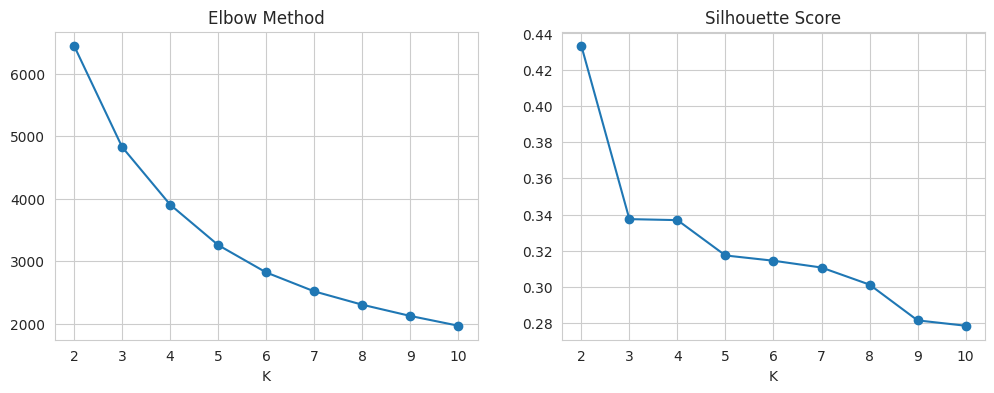

{2: np.float64(0.433), 3: np.float64(0.337), 4: np.float64(0.337), 5: np.float64(0.317), 6: np.float64(0.315), 7: np.float64(0.311), 8: np.float64(0.301), 9: np.float64(0.282), 10: np.float64(0.279)}


In [66]:
inertias, sil_scores = [], []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K_range, inertias, marker="o"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("K")
ax[1].plot(K_range, sil_scores, marker="o"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("K")
plt.show()

print(dict(zip(K_range, np.round(sil_scores, 3))))

In [67]:
def profile_k(k):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X)
    tmp = rfm[["Recency", "Frequency", "Monetary"]].copy()
    tmp["Cluster"] = labels
    prof = tmp.groupby("Cluster").agg(
        Recency=("Recency", "mean"),
        Frequency=("Frequency", "mean"),
        Monetary=("Monetary", "mean"),
        Customers=("Recency", "size"),
    ).round(1)
    prof["% Customers"] = (prof["Customers"] / prof["Customers"].sum() * 100).round(1)
    print(f"\n===== K = {k} | silhouette = {silhouette_score(X, labels):.3f} =====")
    print(prof)

profile_k(4)
profile_k(6)


===== K = 4 | silhouette = 0.337 =====
         Recency  Frequency  Monetary  Customers  % Customers
Cluster                                                      
0          186.4        1.3     332.5       1580         36.6
1           12.0       13.5    7529.3        707         16.4
2           18.8        2.1     521.9        839         19.4
3           69.6        4.0    1600.9       1195         27.7

===== K = 6 | silhouette = 0.315 =====
         Recency  Frequency  Monetary  Customers  % Customers
Cluster                                                      
0          112.6        2.6    1051.8        958         22.2
1           10.4        3.8    1153.8        602         13.9
2          233.9        1.2     250.9        981         22.7
3            7.0       20.7   12985.5        315          7.3
4           38.2        1.4     303.2        800         18.5
5           38.8        6.9    2884.2        665         15.4


In [68]:
print({k: round(float(s), 3) for k, s in zip(K_range, sil_scores)})

{2: 0.433, 3: 0.337, 4: 0.337, 5: 0.317, 6: 0.315, 7: 0.311, 8: 0.301, 9: 0.282, 10: 0.279}


                 Recency  Frequency  Monetary
Segment                                      
At Risk             88.5        2.5     843.8
Lost               239.0        1.0     226.2
Loyal Customers     30.0        6.0    2445.7
New / One-time      34.5        1.0     290.5
Promising            9.0        4.0     973.3
VIP Champions        4.0       15.0    5669.6


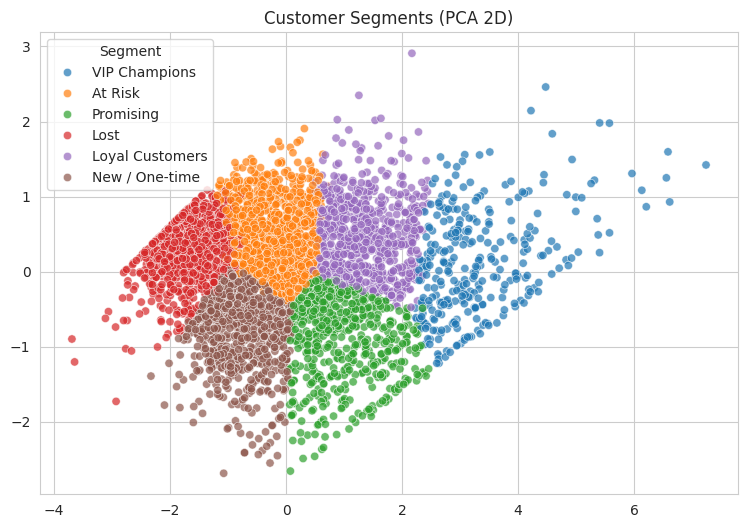

Explained variance: [0.75 0.19]


In [69]:
from sklearn.decomposition import PCA

kmeans = KMeans(n_clusters=6, init="k-means++", n_init=10, random_state=42)
rfm["Cluster"] = kmeans.fit_predict(X)

segment_names = {
    3: "VIP Champions",
    5: "Loyal Customers",
    1: "Promising",
    4: "New / One-time",
    0: "At Risk",
    2: "Lost",
}
rfm["Segment"] = rfm["Cluster"].map(segment_names)

# Median profile
print(rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].median().round(1))

# PCA visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=rfm["Segment"], palette="tab10", alpha=0.7)
plt.title("Customer Segments (PCA 2D)")
plt.show()

print("Explained variance:", pca.explained_variance_ratio_.round(2))

In [70]:
for seed in [0, 1, 7, 21, 42, 99]:
    km = KMeans(n_clusters=6, init="k-means++", n_init=10, random_state=seed)
    labels = km.fit_predict(X)
    print(seed, round(silhouette_score(X, labels), 3))

0 0.314
1 0.314
7 0.315
21 0.315
42 0.315
99 0.314


In [71]:
seg = rfm.groupby("Segment").agg(
    Customers=("Recency", "size"),
    Revenue=("Monetary", "sum"),
)
seg["% Customers"] = (seg["Customers"] / seg["Customers"].sum() * 100).round(1)
seg["% Revenue"] = (seg["Revenue"] / seg["Revenue"].sum() * 100).round(1)
print(seg.sort_values("% Revenue", ascending=False))

                 Customers     Revenue  % Customers  % Revenue
Segment                                                       
VIP Champions          315  4090420.39          7.3       49.9
Loyal Customers        665  1918006.11         15.4       23.4
At Risk                958  1007663.38         22.2       12.3
Promising              602   694576.90         13.9        8.5
Lost                   981   246181.82         22.7        3.0
New / One-time         800   242575.30         18.5        3.0


In [72]:
rfm.to_csv("customer_segments.csv")

In [74]:
import os
os.makedirs("images", exist_ok=True)
plt.savefig("images/pca_segments.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>